# Ingeniería de características
### Objetivo y alcance
La ingeniería de caracteristicas es una etapa crucial en el preprocesado.  Es util para limpiar y obtener caracterísitcas de entrada útiles en los modelos a desarrollar.


## Construcción
### Preparación del conjunto

Parte de la ingeniería de características conlleva a aprovechar el conocimiento que se tiene sobr ela aplicación y es que los objetos a detectar son proporcionales o asociados a una persona.  
Una primer aproximación lleva a generar datos de las cabezas para calcular dimensiones relativas de los objetos:

In [12]:
from pathlib import Path

import cv2
import pandas as pd


IMAGE_DIR = Path("../DataCapture/raw")
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

# Ajustables: un píxel se considera "negro" si sus canales B, G y R
# están dentro de este rango.
BLACK_MAX = 40

# Filtros iniciales para descartar ruido y regiones improbables.
MIN_WIDTH_PX = 20
MIN_HEIGHT_PX = 20
MIN_AREA_REL = 0.001
MAX_AREA_REL = 0.20
MIN_RECTANGULARITY = 0.60
MIN_ASPECT_RATIO = 0.35
MAX_ASPECT_RATIO = 2.00

rows = []

for image_path in sorted(IMAGE_DIR.iterdir()):
    if image_path.suffix.lower() not in EXTENSIONS:
        continue

    image = cv2.imread(str(image_path))
    if image is None:
        print(f"No se pudo leer: {image_path.name}")
        continue

    image_height, image_width = image.shape[:2]
    image_area = image_width * image_height

    # Máscara blanca para píxeles cercanos al negro.
    black_mask = cv2.inRange(
        image,
        (0, 0, 0),
        (BLACK_MAX, BLACK_MAX, BLACK_MAX)
    )

    # Cada región negra conectada devuelve x, y, ancho, alto y área.
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
        black_mask,
        connectivity=8
    )

    # La etiqueta 0 es el fondo de la máscara; se omite.
    for label in range(1, num_labels):
        x, y, w, h, pixel_area = stats[label]

        area_rel = pixel_area / image_area
        aspect_ratio = w / h if h else 0
        rectangularity = pixel_area / (w * h) if w * h else 0

        if w < MIN_WIDTH_PX or h < MIN_HEIGHT_PX:
            continue
        if not MIN_AREA_REL <= area_rel <= MAX_AREA_REL:
            continue
        if not MIN_ASPECT_RATIO <= aspect_ratio <= MAX_ASPECT_RATIO:
            continue
        if rectangularity < MIN_RECTANGULARITY:
            continue

        rows.append({
            "imagen": image_path.name,
            "head_id": sum(r["imagen"] == image_path.name for r in rows) + 1,
            "x": int(x),
            "y": int(y),
            "w": int(w),
            "h": int(h),
            "centro_x": float(centroids[label][0]),
            "centro_y": float(centroids[label][1]),
            "area_relativa": area_rel,
            "aspect_ratio": aspect_ratio,
            "rectangularidad": rectangularity,
        })

head_df = pd.DataFrame(rows)

head_df.head()
head_df.to_csv("../DataCapture/mediciones_mascara_rostro.csv", index=False)


In [26]:
from pathlib import Path

import cv2
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

IMAGE_DIR = Path("../DataCapture/raw")
CSV_PATH = Path("../DataCapture/anotaciones.csv")

annotations = pd.read_csv(CSV_PATH)
heads = pd.read_csv("../DataCapture/mediciones_mascara_rostro.csv")
heads = heads.groupby("imagen").agg({"x": "mean", "y": "mean", "w": "mean", "h": "mean"}).reset_index()

required = {"imagen", "x", "y", "w", "h"}
missing = required - set(annotations.columns)
if missing:
    raise ValueError(f"Faltan columnas en el CSV: {sorted(missing)}")

records = []

for row in annotations.itertuples(index=False):
    image_path = IMAGE_DIR / Path(row.imagen).name
    image = cv2.imread(str(image_path))
    head_data = heads[heads["imagen"] == row.imagen]

    if image is None:
        print(f"No se pudo leer: {image_path.name}")
        continue

    #image_height, image_width = image.shape[:2]
    image_height=np.mean(head_data["h"])
    image_width=np.mean(head_data["w"])
    x, y, w, h = map(float, (row.x, row.y, row.w, row.h))

    if w <= 0 or h <= 0:
        print(f"Caja inválida en {image_path.name}")
        continue

    records.append({
        "imagen": image_path.name,  # identificador; no predictor
        "x": x,
        "y": y,
        "w": w,
        "h": h,
        "image_width": image_width,
        "image_height": image_height,
        "center_x_norm": (x + w / 2) / image_width,
        "center_y_norm": (y + h / 2) / image_height,
        "box_width_rel": w / image_width,
        "box_height_rel": h / image_height,
        "box_area_rel": (w * h) / (image_width * image_height),
        "box_aspect_ratio": w / h,
    })

features_df = pd.DataFrame(records)
features_df.head()


,imagen,x,y,w,h,image_width,image_height,center_x_norm,center_y_norm,box_width_rel,box_height_rel,box_area_rel,box_aspect_ratio
0,captura_20261003_153016_534962.jpg,219.0,387.0,39.0,59.0,170.0,262.0,1.402941,1.589695,0.229412,0.225191,0.051661,0.661017
1,captura_20261003_153021_540685.jpg,396.0,382.0,37.0,52.0,105.5,135.5,3.928910,3.011070,0.350711,0.383764,0.134590,0.711538
2,captura_20261003_153051_624221.jpg,259.0,203.0,11.0,14.0,104.5,90.0,2.531100,2.333333,0.105263,0.155556,0.016374,0.785714
3,captura_20261003_153056_648946.jpg,294.0,300.0,11.0,11.0,243.5,191.0,1.229979,1.599476,0.045175,0.057592,0.002602,1.000000
4,captura_20261003_153101_657504.jpg,244.0,217.0,15.0,13.0,233.5,222.5,1.077088,1.004494,0.064240,0.058427,0.003753,1.153846


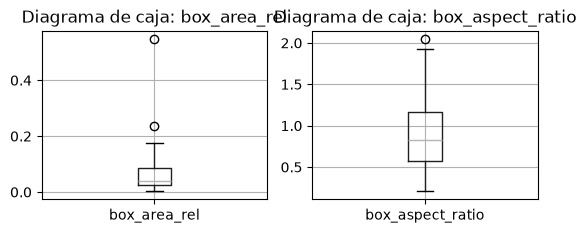

In [30]:
for col in ["box_area_rel", "box_aspect_ratio"]:
    plt.subplot(2, 2, 3 if col == "box_area_rel" else 4)
    features_df.boxplot(column=col)
    plt.title(f"Diagrama de caja: {col}")

Se observa que los objetos a encontrar respecto al tamaño de la cabena caen en escalas pequeñas y con sesgo hacia arriba, de igual manera el amontonamiento ocurre en escalas bajas.  En cuanto a la forma se observa una aproximación casi cuadrada abarcando varias geometrías.

### Generación de características

In [ ]:
# Generar y extraer características útiles de las imagenes y sus anotaciones. 
# Se calculan características como el centro normalizado de la caja delimitadora, el tamaño relativo de la caja y la relación de aspecto.
# Estas características pueden ser útiles para entrenar modelos de aprendizaje automático.



## Normalización

### Distribuciones y binning

In [6]:
# Usar transformaciones (log1p) o algo del estilo
# Se obtienen distribuciones o efectos a mejorar las caracteristicas de entrada.


## Selección/extracción
### Codificación y escalamiento


### Seleccion de características

### Extracción

## Conclusiones